# Preprocessing 데이터 검증

- 작성자: byhyun
- 상태: 완료
- 작성일: 2026-11-17
- 관련 작업: T06 (전처리 공통 함수 실데이터 검증, ELA·Crop·평가 규칙의 근거 확인)
- [보고서](../../docs/eda/EXP_byhyun_001_preprocessing_check.md) · [참조 보고서](../../docs/eda/EXP_kimjaehak_002_dataset_eda.md)

전처리 공통 함수([preprocessing.py](../../scripts/preprocessing.py))의 전제가 실제 AutoSplice 데이터에서 [문서](../../docs/preprocessing.md)대로 지켜지는지 확인하고, 팀이 정해야 하는 ELA 설정·크롭 정책·평가 규칙의 근거를 만듦. 모델 학습이 있어야 정할 수 있는 항목(ELA 최종 설정, 임계값)은 이 노트북에서 정하지 않고 학습 비교로 넘김.

`preprocessing.py`는 수정하지 않고 import해서 사용함. 수정이 필요한 부분은 근거만 기록하고 별도로 제안함. 모델 학습은 하지 않으며 표본은 고정 seed(42)로 뽑음. 설정 비교에는 AutoSplice train 이미지를 사용하고, 후보는 val 이미지로 다시 확인함. AutoSplice test와 CocoGlide는 사용하지 않음. ELA 비교는 성능이 아닌 참고용 지표이며, 최종 ELA 설정은 val 성능과 팀의 합의로 결정함.

### 1. Colab 환경 설정

Colab 환경, 공유 Drive 경로, ZIP 준비, 고정 분할 연결은 [EXP_kimjaehak_001](EXP_kimjaehak_001_evaluation_example.ipynb)의 1~3절과 유사한 코드로 진행한다. 공유 Drive의 `AI_Forensics/project`에서 공통 코드를 읽고, 데이터 ZIP은 해시를 확인한 뒤 Colab 런타임에 푼다. 분할 CSV의 해시가 공유본과 다르면 중단한다.

AutoSplice는 JPEG 품질 100 파일만 사용하며, 이 노트북에서 분할을 다시 만들지 않는다. 설정은 train 조작 이미지로 비교하고 val 조작 이미지로 다시 확인하며, 표본은 고정 seed(42)로 뽑는다. CocoGlide는 외부 테스트용이므로 이 노트북에서 사용하지 않는다. 실행한 패키지 버전과 preprocessing.py, datasets.py, 분할 CSV의 SHA-256은 아래 출력으로 기록한다.

In [1]:
from pathlib import Path
from google.colab import drive

drive.mount("/content/drive")
shared_root = Path("/content/drive/MyDrive/AI_Forensics")
project_root = shared_root / "project"
archive_paths = {
    "AutoSplice": shared_root / "datasets/AutoSplice/AutoSplice.zip",
    "CocoGlide": shared_root / "datasets/CocoGlide.zip",
}
work_root = Path("/content")
data_root = work_root / "datasets"
extract_paths = {"AutoSplice": data_root, "CocoGlide": data_root / "CocoGlide"}
split_path = project_root / "scripts/splits/autosplice_seed42.csv"

if not (project_root / "scripts/preprocessing.py").is_file():
    raise FileNotFoundError("공유 Drive의 AI_Forensics/project에 공통 코드를 준비해야 함.")

print("실행 환경: Colab 런타임")
print("프로젝트:", project_root)
print("데이터 해제 위치:", data_root)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
실행 환경: Colab 런타임
프로젝트: /content/drive/MyDrive/AI_Forensics/project
데이터 해제 위치: /content/datasets


In [2]:
import importlib.metadata
import platform
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

sys.path.insert(0, str(project_root))
from scripts.preprocessing import load_rgb, load_binary_mask, crop_pair, make_ela
from scripts.datasets import sha256, prepare_dataset_zip, autosplice_records, cocoglide_records

print("Python:", platform.python_version())
print("OS:", platform.platform())
for package in ("numpy", "Pillow", "pandas", "matplotlib"):
    print(package, importlib.metadata.version(package))
print("GPU: 사용하지 않음")
print("코드 기준: 커밋 전 파일, 아래 SHA-256으로 기록함.")
for relative in ("scripts/preprocessing.py", "scripts/datasets.py", "scripts/splits/autosplice_seed42.csv"):
    print(relative, sha256(project_root / relative))

mask_foreground = 255
seed = 42
print("설정:", dict(mask_foreground=mask_foreground, autosplice_quality=100, seed=seed))

Python: 3.13.18
OS: Linux-6.6.159+-x86_64-with-glibc2.39
numpy 2.4.6
Pillow 11.3.0
pandas 2.2.3
matplotlib 3.10.0
GPU: 사용하지 않음
코드 기준: 커밋 전 파일, 아래 SHA-256으로 기록함.
scripts/preprocessing.py 69809276be12200a3cd2ef1e96364a7d168b39cae0a2cce1946f84d7ce74db07
scripts/datasets.py 435215ef08c2c43ce2f84795d783895074eee85f8e062f28ea8ee6acabad3e88
scripts/splits/autosplice_seed42.csv f8a2893ab93b82264e6434fa0c26f09472de05bd98829065c2a0db846ace7b1e
설정: {'mask_foreground': 255, 'autosplice_quality': 100, 'seed': 42}


In [3]:
archive_hashes = {
    "AutoSplice": "0d94e2df6842f44c11e21ee207707c49fd9717ec89048bd6f28fc1e07c4a5e36",
    "CocoGlide": "fc848643ad0a81010ba2a6ab8c055762782f54e4fb9e407210dbfe1c3b538af9",
}

for name, source in archive_paths.items():
    prepare_dataset_zip(source, work_root / f"{name}.zip", extract_paths[name], archive_hashes[name])

expected_split_hash = "f8a2893ab93b82264e6434fa0c26f09472de05bd98829065c2a0db846ace7b1e"
if sha256(split_path) != expected_split_hash:
    raise ValueError("공유한 분할 CSV와 일치해야 함.")

split_table = pd.read_csv(split_path, dtype=str)
display(split_table.groupby("split").size().reindex(["train", "val", "test"]).rename("original_ids").to_frame())

auto_records = autosplice_records(data_root / "AutoSplice", split_path, 100)
coco_records = cocoglide_records(data_root / "CocoGlide")

auto_table = pd.DataFrame(auto_records)
coco_table = pd.DataFrame(coco_records)
display(auto_table.groupby(["split", "kind"]).size().unstack().reindex(["train", "val", "test"]))
display(coco_table.groupby(["split", "kind"]).size().unstack())

train_forged = [r for r in auto_records if r["split"] == "train" and r["kind"] == "manipulated"]

def pick(records, n, seed=seed):
    idx = np.random.default_rng(seed).choice(len(records), size=min(n, len(records)), replace=False)
    return [records[i] for i in sorted(idx)]

print("train 조작 이미지 수:", len(train_forged))

AutoSplice 기존 해제 파일 사용
CocoGlide 기존 해제 파일 사용


,original_ids
split,
train,1818
val,227
test,228


kind,manipulated,normal
split,,
train,2925,1818
val,361,227
test,335,228


kind,manipulated,normal
split,,
external_test,512,512


train 조작 이미지 수: 2925


### 2. 이미지·마스크 정합성과 Crop 확인

값을 정하기 전에 전처리의 전제가 실제 데이터에서 지켜지는지 확인한다. AutoSplice train 조작 이미지 전체에서 이미지·마스크·정상 원본 파일의 헤더를 읽어, 세 파일의 크기가 서로 일치하는지와 EXIF 방향 태그가 다른 파일이 있는지 확인한다.

`crop_pair`가 이미지와 마스크를 같은 위치로 자르는지, 결과가 복사본인지 확인한다. 이어서 제안서 규칙("Crop한 뒤 ELA를 만들고, 같은 좌우 반전을 세 배열에 적용한다")과 다른 순서로 처리하면 ELA가 얼마나 달라지는지 확인한다. 

JPEG는 블록 단위로 압축하며 블록 크기는 subsampling 0에서 8×8, 2에서 16×16이므로, Crop 시작 위치에 따라 Crop 후 ELA와 전체 ELA 후 Crop이 달라질 수 있다. 시작 위치가 블록의 배수일 때와 아닐 때를 나누어 비교하고, 뒤집은 뒤 ELA를 다시 계산하는 순서와 ELA를 뒤집는 순서도 비교한다. 이 비교는 가로·세로가 모두 320 이상인 train 조작 이미지 41장 중 20장으로 한다.

이미지·마스크 크기 불일치: 0 / 2925
조작·정상 원본 크기 불일치: 0 / 2925
EXIF 방향 값 (조작/마스크/정상): {1: 2925} {1: 2925} {1: 2925}


,w,h
count,2925.0,2925.0
mean,363.8,296.7
std,200.0,200.0
min,256.0,256.0
25%,256.0,256.0
50%,378.0,256.0
75%,384.0,294.0
max,3744.0,3744.0


Crop이 슬라이싱과 동일: True
Crop이 복사본: True
가로·세로 320 이상 이미지 수: 41
[표 1] 크롭한 뒤 ELA vs 전체 ELA 후 크롭: '값이 다른 픽셀 비율'이 0%에 가까울수록 두 방식이 같음


,subsampling,"크롭 시작 위치(행,열)",이미지 수,값이 다른 픽셀 비율,가장 큰 값 차이(0~255)
0,0 (4:4:4),"(16,32)",20,0.0%,0
1,0 (4:4:4),"(8,8)",20,0.0%,0
2,0 (4:4:4),"(5,3)",20,53.3%,255
3,2 (4:2:0),"(16,32)",20,0.3%,165
4,2 (4:2:0),"(8,8)",20,32.9%,255
5,2 (4:2:0),"(5,3)",20,54.3%,255


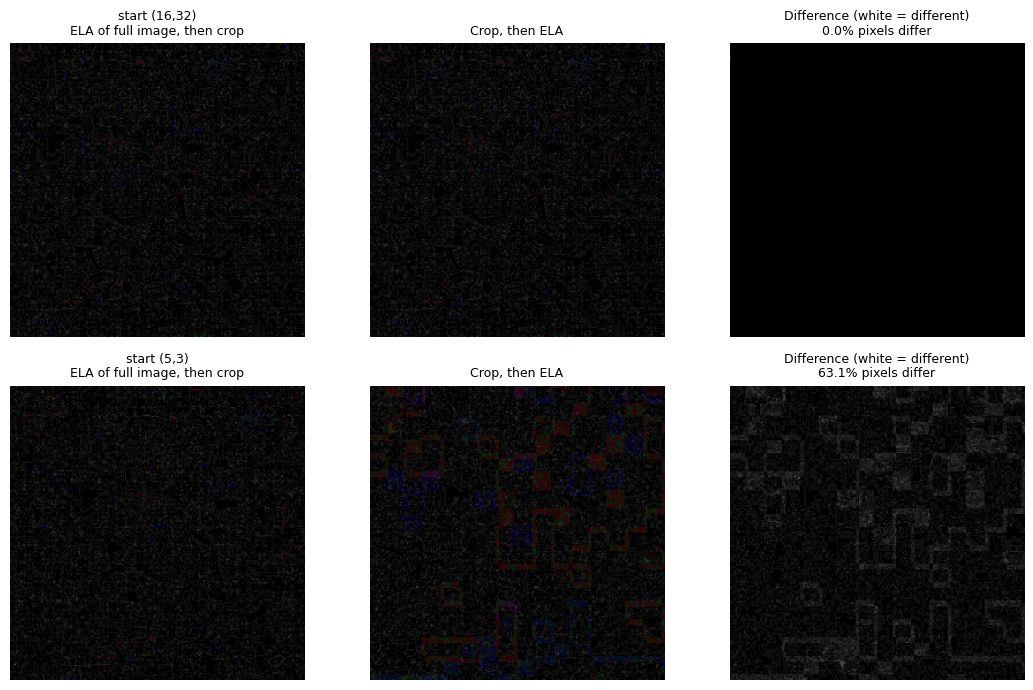

[표 2] ELA를 만든 뒤 좌우 뒤집기 vs 뒤집은 뒤 ELA 만들기: 0%에 가까울수록 두 순서가 같음


,subsampling,이미지 수,값이 다른 픽셀 비율,가장 큰 값 차이(0~255)
0,0 (4:4:4),20,0.5%,75
1,1 (4:2:2),20,8.1%,195
2,2 (4:2:0),20,7.0%,195


In [4]:
from PIL import Image

rows = []
for r in train_forged:
    with Image.open(r["image_path"]) as a, Image.open(r["mask_path"]) as b, Image.open(r["real_path"]) as c:
        rows.append(dict(w=a.size[0], h=a.size[1], mw=b.size[0], mh=b.size[1], rw=c.size[0], rh=c.size[1],
                         exif_img=a.getexif().get(274, 1), exif_mask=b.getexif().get(274, 1),
                         exif_real=c.getexif().get(274, 1)))
size_df = pd.DataFrame(rows)
print("이미지·마스크 크기 불일치:", int(((size_df.w != size_df.mw) | (size_df.h != size_df.mh)).sum()), "/", len(size_df))
print("조작·정상 원본 크기 불일치:", int(((size_df.w != size_df.rw) | (size_df.h != size_df.rh)).sum()), "/", len(size_df))
print("EXIF 방향 값 (조작/마스크/정상):", size_df.exif_img.value_counts().to_dict(),
      size_df.exif_mask.value_counts().to_dict(), size_df.exif_real.value_counts().to_dict())
display(size_df[["w", "h"]].describe().round(1))

samples = pick(train_forged, 5)
row = samples[0]
rgb = load_rgb(row["image_path"])
mask = load_binary_mask(row["mask_path"], foreground_value=mask_foreground)
top, left, h, w = 16, 32, 128, 160
c_rgb, c_mask = crop_pair(rgb, mask, top=top, left=left, height=h, width=w)
print("Crop이 슬라이싱과 동일:", np.array_equal(c_rgb, rgb[top:top+h, left:left+w]) and np.array_equal(c_mask, mask[top:top+h, left:left+w]))
before = rgb.copy(); c_rgb[...] = 0
print("Crop이 복사본:", np.array_equal(rgb, before))

sizes = list(zip(size_df.w, size_df.h))
big_records = [r for r, (w_, h_) in zip(train_forged, sizes) if min(w_, h_) >= 320]
print("가로·세로 320 이상 이미지 수:", len(big_records))
big = [load_rgb(r["image_path"]) for r in pick(big_records, 20)]

def ela_pair(x, top, left, sub, size=256):
    """같은 위치를 두 방식으로 만든 ELA를 반환: (전체 ELA 후 크롭, 크롭 후 ELA)"""
    full_then_crop = make_ela(x, quality=75, scale=15, subsampling=sub)[top:top+size, left:left+size]
    crop_then_ela = make_ela(x[top:top+size, left:left+size].copy(), quality=75, scale=15, subsampling=sub)
    return full_then_crop, crop_then_ela

sub_name = {0: "0 (4:4:4)", 1: "1 (4:2:2)", 2: "2 (4:2:0)"}

# [표 1] 크롭 위치에 따라 두 방식의 ELA가 얼마나 다른가
rows = []
for sub in (0, 2):
    for top, left in [(16, 32), (8, 8), (5, 3)]:
        diffs = []
        for x in big:
            a, b = ela_pair(x, top, left, sub)
            diffs.append(np.abs(a.astype(int) - b.astype(int)))
        rows.append({"subsampling": sub_name[sub], "크롭 시작 위치(행,열)": f"({top},{left})",
                     "이미지 수": len(diffs),
                     "값이 다른 픽셀 비율": f"{np.mean([(d > 0).mean() for d in diffs]) * 100:.1f}%",
                     "가장 큰 값 차이(0~255)": int(max(d.max() for d in diffs))})
print("[표 1] 크롭한 뒤 ELA vs 전체 ELA 후 크롭: '값이 다른 픽셀 비율'이 0%에 가까울수록 두 방식이 같음")
display(pd.DataFrame(rows))

# [그림 1] 이미지 한 장으로 직접 보기 (subsampling 2)
fig, axes = plt.subplots(2, 3, figsize=(11, 7))
for i, (top, left) in enumerate([(16, 32), (5, 3)]):
    a, b = ela_pair(big[0], top, left, 2)
    d = np.abs(a.astype(int) - b.astype(int)).max(axis=2)
    axes[i, 0].imshow(a); axes[i, 0].set_title(f"start ({top},{left})\nELA of full image, then crop", fontsize=9)
    axes[i, 1].imshow(b); axes[i, 1].set_title("Crop, then ELA", fontsize=9)
    axes[i, 2].imshow(d, cmap="gray", vmin=0, vmax=255)
    axes[i, 2].set_title(f"Difference (white = different)\n{(d > 0).mean() * 100:.1f}% pixels differ", fontsize=9)
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout(); plt.show()

# [표 2] ELA를 만든 뒤 뒤집기 vs 뒤집은 뒤 ELA 만들기
rows = []
for sub in (0, 1, 2):
    diffs = []
    for x in big:
        c = x[:256, :256].copy()
        a = make_ela(c, quality=75, scale=15, subsampling=sub)[:, ::-1]
        b = make_ela(np.ascontiguousarray(c[:, ::-1]), quality=75, scale=15, subsampling=sub)
        diffs.append(np.abs(a.astype(int) - b.astype(int)))
    rows.append({"subsampling": sub_name[sub], "이미지 수": len(diffs),
                 "값이 다른 픽셀 비율": f"{np.mean([(d > 0).mean() for d in diffs]) * 100:.1f}%",
                 "가장 큰 값 차이(0~255)": int(max(d.max() for d in diffs))})
print("[표 2] ELA를 만든 뒤 좌우 뒤집기 vs 뒤집은 뒤 ELA 만들기: 0%에 가까울수록 두 순서가 같음")
display(pd.DataFrame(rows))

### 3. ELA 수치 처리 결정

`make_ela`의 반올림 방식과 곱셈 전 클리핑이 결과를 바꾸는지 확인하고자 한다.

`np.rint`는 정확히 .5인 값을 가장 가까운 짝수로 반올림한다. 차이 × scale이 정수이면 일반적인 반올림(.5는 올림)과 결과가 같고, scale이 소수일 때만 차이가 생길 수 있다. 같은 이미지에서 두 방식이 다르게 나온 값의 비율을 scale별로 구한다.

`make_ela`는 큰 배율에서 곱셈이 넘치지 않도록 차이를 255 / scale로 먼저 제한한다. 이 제한이 결과를 바꾸지 않으면 단순화할 수 있으므로, 제한을 뺀 계산과 값이 같은지 확인한다. 직접 구현한 기준 계산이 `make_ela`와 같은 값을 내는지도 함께 확인한다(표의 ref_vs_make_ela).


In [5]:
from io import BytesIO

def recompress(rgb, quality, subsampling):
    with BytesIO() as buf:
        Image.fromarray(rgb).save(buf, format="JPEG", quality=quality, subsampling=subsampling,
                                  optimize=False, progressive=False)
        buf.seek(0)
        with Image.open(buf) as im:
            return np.array(im.convert("RGB"), dtype=np.uint8)

def ela_ref(rgb, quality, scale, subsampling, rounding="rint", clamp=True):
    d = np.abs(rgb.astype(np.float64) - recompress(rgb, quality, subsampling).astype(np.float64))
    if clamp and scale > 1:
        d = np.minimum(d, 255.0 / scale)
    v = d * scale
    v = np.rint(v) if rounding == "rint" else np.floor(v + 0.5)
    return np.clip(v, 0, 255).astype(np.uint8)

crops = [load_rgb(r["image_path"])[:256, :256].copy() for r in pick(train_forged, 5, seed=seed + 1)]
rows = []
for scale in (15, 10, 7.5, 5, 1.5, 0.5, 1000):
    d_round = d_clamp = d_vs_make = total = 0
    for x in crops:
        a = ela_ref(x, 75, scale, 2, "rint", True)
        b = ela_ref(x, 75, scale, 2, "half_up", True)
        c = ela_ref(x, 75, scale, 2, "rint", False)
        m = make_ela(x, quality=75, scale=scale, subsampling=2)
        d_round += int((a != b).sum()); d_clamp += int((a != c).sum()); d_vs_make += int((a != m).sum()); total += a.size
    rows.append(dict(scale=scale, rint_vs_half_up=round(d_round / total, 4),
                     clamp_vs_noclamp=round(d_clamp / total, 4), ref_vs_make_ela=round(d_vs_make / total, 4)))
display(pd.DataFrame(rows))

,scale,rint_vs_half_up,clamp_vs_noclamp,ref_vs_make_ela
0,15.0,0.0000,0.0,0.0
1,10.0,0.0000,0.0,0.0
2,7.5,0.0737,0.0,0.0
3,5.0,0.0000,0.0,0.0
4,1.5,0.0738,0.0,0.0
5,0.5,0.2838,0.0,0.0
6,1000.0,0.0000,0.0,0.0


### 4. ELA 설정과 압축 이력

#### (1) 파일의 JPEG 저장 이력 확인 및 비교

정상 원본과 조작본이 어떤 JPEG 설정으로 저장되어 있는지 확인한다. 

ELA는 이미지를 정해진 품질로 다시 압축했을 때 값이 얼마나 변하는지 보는 것이다. 파일이 이미 같은 품질·subsampling으로 저장되어 있으면 다시 압축해도 거의 변하지 않아 ELA가 0에 가깝다. 정상 원본과 조작본의 저장 설정이 다르면 모델이 조작 영역이 아니라 이 차이를 단서로 쓸 수 있다.

 파일의 양자화 테이블에서 품질을 추정하고(표준 JPEG 테이블과 합이 가장 가까운 품질을 고른다) subsampling을 읽는다. 추정값이므로 standard_table 비율이 낮으면 표준 테이블이 아닌 파일이 많다는 뜻이다. 아래 셀은 train 조작 이미지 200장에서 정상 원본과 조작본 각각의 파일 형식, 추정 품질, 표준 테이블 비율, subsampling을 센다.


In [6]:
STD_LUMA = [16, 11, 10, 16, 24, 40, 51, 61, 12, 12, 14, 19, 26, 58, 60, 55,
            14, 13, 16, 24, 40, 57, 69, 56, 14, 17, 22, 29, 51, 87, 80, 62,
            18, 22, 37, 56, 68, 109, 103, 77, 24, 35, 55, 64, 81, 104, 113, 92,
            49, 64, 78, 87, 103, 121, 120, 101, 72, 92, 95, 98, 112, 100, 103, 99]

def scaled_table(q):
    s = 5000 // q if q < 50 else 200 - 2 * q
    return [min(max((v * s + 50) // 100, 1), 255) for v in STD_LUMA]

SCALED = {q: scaled_table(q) for q in range(1, 101)}

def jpeg_history(path):
    with Image.open(path) as im:
        tables = getattr(im, "quantization", None)
        if im.format != "JPEG" or not tables or 0 not in tables:
            return dict(format=im.format, quality="-", standard_table=False, subsampling="-")
        luma = list(tables[0])
        q = min(SCALED, key=lambda k: abs(sum(SCALED[k]) - sum(luma)))
        return dict(format=im.format, quality=q, standard_table=sorted(luma) == sorted(SCALED[q]),
                    subsampling=JpegImagePlugin.get_sampling(im))

from PIL import JpegImagePlugin
history = pd.DataFrame([dict(group=group, **jpeg_history(r[key]))
                        for r in pick(train_forged, 200)
                        for group, key in (("정상 원본", "real_path"), ("조작본", "image_path"))])
for group, g in history.groupby("group"):
    print(f"[{group}] {len(g)}장")
    print("  파일 형식:", g["format"].value_counts().to_dict())
    print("  추정 품질 (상위 5개):", g["quality"].value_counts().head(5).to_dict())
    print("  표준 테이블 비율:", round(float(g["standard_table"].mean()), 3))
    print("  subsampling (0=4:4:4, 1=4:2:2, 2=4:2:0):", g["subsampling"].value_counts().to_dict())

[정상 원본] 200장
  파일 형식: {'JPEG': 200}
  추정 품질 (상위 5개): {75: 200}
  표준 테이블 비율: 1.0
  subsampling (0=4:4:4, 1=4:2:2, 2=4:2:0): {2: 200}
[조작본] 200장
  파일 형식: {'JPEG': 200}
  추정 품질 (상위 5개): {100: 200}
  표준 테이블 비율: 1.0
  subsampling (0=4:4:4, 1=4:2:2, 2=4:2:0): {2: 200}



#### (2) ELA 설정 후보 수치 비교 및 확인

ELA 설정 후보를 train 표본에서 수치로 비교해 후보를 줄이고, val 표본에서 다시 확인한다.

AutoSplice train 조작 이미지 100장에서 scale을 10으로 고정하고 quality 75·90·95, subsampling 0·2의 6개 조합을 비교한다. scale은 ELA 값에 상수를 곱할 뿐이라 AUROC에 영향을 주지 않으므로, AUROC로는 (quality, subsampling)만 비교하고 scale은 따로 정한다. 조합마다 아래 값을 구한다.

----
- auroc: 픽셀 하나의 ELA 값(세 채널의 최댓값)을 점수로 보았을 때 조작·정상 픽셀을 얼마나 구분하는지를 나타낸다. 0.5는 무작위와 같다. 이미지마다 20,000개 픽셀을 뽑아 계산하고 이미지별 값을 평균한다. 모델 없이 ELA 값만 쓴 참고 지표이며 U-Net의 성능이 아니다.

- leak_ratio: (정상 원본의 평균 ELA) / (조작 이미지의 조작 영역 밖 평균 ELA). 조작하지 않은 영역은 대체로 정상 원본과 같은 내용(5절에서 확인)이므로, 값이 1에 가까우면 ELA에서 비슷하게 보인다. 1보다 훨씬 작으면 조작하지 않은 영역에도 ELA 값이 남아 있어서, 모델이 조작 영역이 아니라 파일의 압축 이력 차이를 단서로 삼을 수 있다. 평균 하나로 본 값이라 1에 가깝다는 것이 두 이미지가 같다는 뜻은 아니며, 큰 차이를 알려 주는 참고 지표로만 사용한다.

- saturated: ELA 값이 255로 잘려 정보가 사라진 픽셀 비율이다.

- zero: 재압축해도 변하지 않아 ELA가 0인 픽셀 비율이다.
----

표의 inside, outside, authentic은 각각 조작 영역 안, 조작 영역 밖, 정상 원본 전체의 평균 ELA이며 leak_ratio를 계산하는 데 쓴다. leak_gap(outside - authentic)은 scale에 비례해서 비교하기 어려우므로 참고만 한다.

quality와 subsampling은 auroc와 leak_ratio를 함께 보고, 위 압축 이력으로 leak_ratio가 작은 이유를 해석한 뒤 후보 2~3개를 사람이 정한다. scale은 후보 설정에서 ELA 원값의 분포와 포화 비율을 보고 정한다.

In [7]:
import itertools

def load_items(records):
    return [dict(rgb=load_rgb(r["image_path"]), real=load_rgb(r["real_path"]),
                 mask=load_binary_mask(r["mask_path"], foreground_value=mask_foreground)) for r in records]

def auroc(score, label):
    pos = label == 1
    n1, n0 = int(pos.sum()), int((~pos).sum())
    if n1 == 0 or n0 == 0:
        return np.nan
    ranks = pd.Series(score).rank().to_numpy()
    return (ranks[pos].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

def evaluate(items, configs, n_pixels=20000):
    rng = np.random.default_rng(seed)
    rows = []
    for it in items:
        mask = it["mask"]
        idx = rng.choice(mask.size, size=min(n_pixels, mask.size), replace=False)
        for q, s, sub in configs:
            gray = make_ela(it["rgb"], quality=q, scale=s, subsampling=sub).max(axis=2)
            gray_real = make_ela(it["real"], quality=q, scale=s, subsampling=sub).max(axis=2)
            outside = float(gray[mask == 0].mean())
            rows.append(dict(Q=q, scale=s, sub=sub,
                             auroc=auroc(gray.ravel()[idx], mask.ravel()[idx]),
                             inside=float(gray[mask == 1].mean()), outside=outside,
                             authentic=float(gray_real.mean()), leak_gap=outside - float(gray_real.mean()),
                             saturated=float((gray == 255).mean()), zero=float((gray == 0).mean())))
    return pd.DataFrame(rows)

# 표본 (train으로 비교, val로 확인)
N = 100
train_items = load_items(pick(train_forged, N))
val_forged = [r for r in auto_records if r["split"] == "val" and r["kind"] == "manipulated"]
val_items = load_items(pick(val_forged, N))

# (quality, subsampling) 비교: scale은 10으로 고정
configs = list(itertools.product((75, 90, 95), (10,), (0, 2)))
train_df = evaluate(train_items, configs)
train_summary = train_df.groupby(["Q", "scale", "sub"]).mean()
train_summary["leak_ratio"] = train_summary["authentic"] / train_summary["outside"]
display(train_summary.sort_values("auroc", ascending=False).round(3))

# scale: ELA 원값(scale=1) 분포와 포화 비율
def raw_sample(items, q, sub, n=20000):
    rng = np.random.default_rng(seed)
    vals = []
    for it in items:
        g = make_ela(it["rgb"], quality=q, scale=1, subsampling=sub).max(axis=2).ravel()
        vals.append(g[rng.choice(g.size, size=min(n, g.size), replace=False)])
    return np.concatenate(vals)

for q, sub in [(75, 2), (90, 2)]:
    raw = raw_sample(train_items, q, sub)
    print(f"Q{q} sub{sub}: 원값 분위수 50/99/99.9% =", np.percentile(raw, [50, 99, 99.9]))
    for s in (5, 10, 15, 20, 30):
        print(f"   scale={s}: 포화 비율 {(raw.astype(np.float64) * s >= 255).mean():.4f}")

# val에서 후보 확인
candidates = [(75, 10, 2), (90, 10, 2), (75, 10, 0)]   # 예시. 표를 보고 직접 정함
val_summary = evaluate(val_items, candidates).groupby(["Q", "scale", "sub"]).mean()
val_summary["leak_ratio"] = val_summary["authentic"] / val_summary["outside"]
display(val_summary.round(3))

,,,auroc,inside,outside,authentic,leak_gap,saturated,zero,leak_ratio
Q,scale,sub,,,,,,,,
75,10,2,0.880,49.206,9.830,0.473,9.357,0.001,0.362,0.048
90,10,2,0.822,33.659,9.862,10.299,-0.437,0.000,0.322,1.044
75,10,0,0.817,38.513,11.733,10.519,1.214,0.000,0.307,0.897
95,10,2,0.809,25.669,7.589,6.473,1.116,0.000,0.380,0.853
90,10,0,0.771,24.897,9.040,10.820,-1.780,0.000,0.340,1.197
95,10,0,0.751,17.666,6.458,6.509,-0.051,0.000,0.419,1.008


Q75 sub2: 원값 분위수 50/99/99.9% = [ 2. 17. 27.]
   scale=5: 포화 비율 0.0000
   scale=10: 포화 비율 0.0014
   scale=15: 포화 비율 0.0100
   scale=20: 포화 비율 0.0259
   scale=30: 포화 비율 0.0697
Q90 sub2: 원값 분위수 50/99/99.9% = [ 1. 11. 18.]
   scale=5: 포화 비율 0.0000
   scale=10: 포화 비율 0.0001
   scale=15: 포화 비율 0.0014
   scale=20: 포화 비율 0.0053
   scale=30: 포화 비율 0.0235


auroc  inside  outside  authentic  leak_gap  saturated   zero  \
Q  scale sub                                                                  
75 10    0    0.784  38.070   13.867     11.653     2.214      0.000  0.287   
         2    0.864  49.430   11.265      1.037    10.228      0.002  0.359   
90 10    2    0.797  33.748   11.510     11.723    -0.213      0.000  0.306   

              leak_ratio  
Q  scale sub              
75 10    0         0.840  
         2         0.092  
90 10    2         1.018

### 5. Crop 정책

학습 이미지에서 Crop할 수 없는 이미지와 조작 영역이 없는 Crop이 얼마나 되는지 확인한다.

제안서는 Crop의 시작 좌표와 크기를 16의 배수로 정했지만, 이미지가 Crop보다 작을 때와 조작 영역이 없는 Crop의 처리는 정하지 않았다. Crop 크기 후보를 128×128, 192×192, 256×256, 320×320으로 정하고, train 조작 이미지 전체에서 이미지마다 시작 좌표가 16의 배수인 Crop 5개를 무작위로 뽑는다. 

후보별로 Crop할 수 없는 이미지 수, 조작 영역이 전혀 없는 Crop의 비율, Crop 안 조작 비율의 중앙값을 구한다. 수치와 함께 조작 영역이 없는 Crop과 조작 영역이 매우 작은(2% 미만) Crop을 이미지로 직접 확인한다.

In [8]:
train_masks = [load_binary_mask(r["mask_path"], foreground_value=mask_foreground) for r in train_forged]

rows = []
for S in (128, 192, 256, 320):
    rng = np.random.default_rng(seed)
    small = total = empty = 0
    ratios = []
    for m in train_masks:
        H, W = m.shape
        if H < S or W < S:
            small += 1
            continue
        for _ in range(5):
            t = int(rng.integers(0, (H - S) // 16 + 1)) * 16
            l = int(rng.integers(0, (W - S) // 16 + 1)) * 16
            c = m[t:t+S, l:l+S]
            total += 1
            empty += int(c.sum() == 0)
            ratios.append(float(c.mean()))
    rows.append(dict(crop=S, too_small_images=small, crops=total,
                     empty_ratio=round(empty / max(total, 1), 4), median_fg_ratio=round(float(np.median(ratios)), 4)))
display(pd.DataFrame(rows))

,crop,too_small_images,crops,empty_ratio,median_fg_ratio
0,128,0,14625,0.0968,0.5886
1,192,0,14625,0.0275,0.5925
2,256,0,14625,0.0088,0.5210
3,320,2884,205,0.1415,0.6852


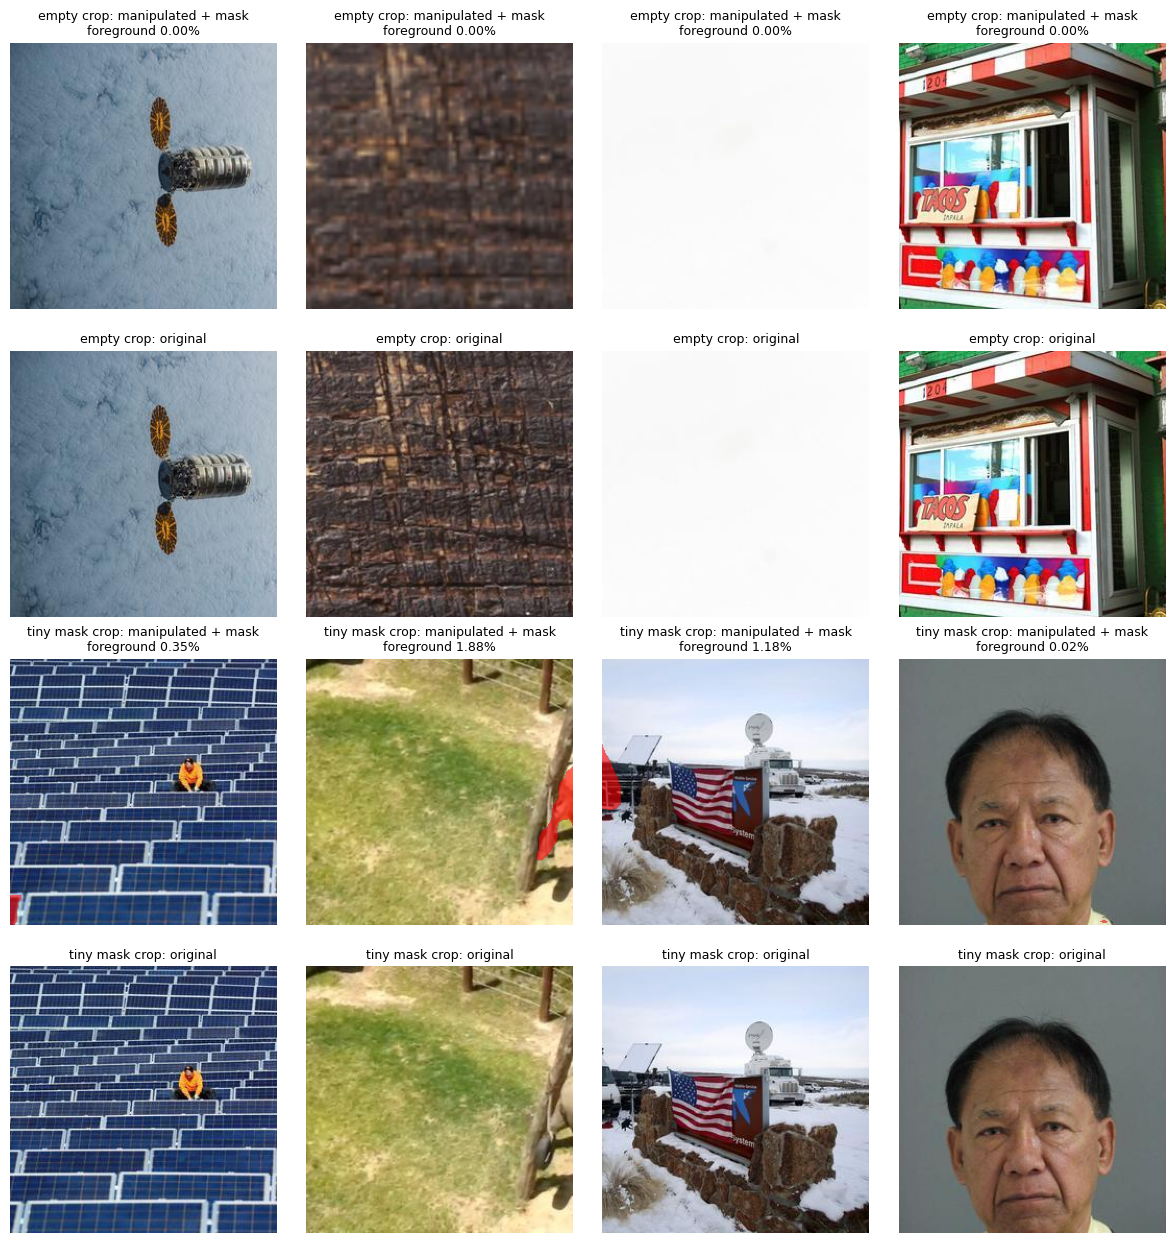

In [9]:
S = 256
rng = np.random.default_rng(seed + 2)
empty_ex, small_ex = [], []
for i in rng.permutation(len(train_forged)):
    H, W = train_masks[i].shape
    t = int(rng.integers(0, (H - S) // 16 + 1)) * 16
    l = int(rng.integers(0, (W - S) // 16 + 1)) * 16
    ratio = float(train_masks[i][t:t+S, l:l+S].mean())
    if ratio == 0 and len(empty_ex) < 4:
        empty_ex.append((i, t, l, ratio))
    elif 0 < ratio < 0.02 and len(small_ex) < 4:
        small_ex.append((i, t, l, ratio))
    if len(empty_ex) == 4 and len(small_ex) == 4:
        break

fig, axes = plt.subplots(4, 4, figsize=(12, 12.5))
for group, (label, examples) in enumerate((("empty crop", empty_ex), ("tiny mask crop", small_ex))):
    for col in range(4):
        ax_fake, ax_real = axes[group * 2, col], axes[group * 2 + 1, col]
        ax_fake.axis("off"); ax_real.axis("off")
        if col >= len(examples):
            continue
        i, t, l, ratio = examples[col]
        fake = load_rgb(train_forged[i]["image_path"])[t:t+S, l:l+S]
        real = load_rgb(train_forged[i]["real_path"])[t:t+S, l:l+S]
        c = train_masks[i][t:t+S, l:l+S]
        ax_fake.imshow(fake)
        if c.any():
            ax_fake.imshow(np.ma.masked_where(c == 0, c), cmap="autumn", alpha=0.6)
        ax_fake.set_title(f"{label}: manipulated + mask\nforeground {ratio:.2%}", fontsize=9)
        ax_real.imshow(real)
        ax_real.set_title(f"{label}: original", fontsize=9)
plt.tight_layout()
plt.show()

이미지에서 각 열의 위쪽은 조작본과 마스크(빨간색), 아래쪽은 같은 위치의 정상 원본이다. 

조작 영역이 없다고 표시된 Crop이 실제로 원본과 같은지 눈으로 비교한다. train 조작 이미지 100장에서 조작본과 원본의 픽셀 차이(세 채널 중 최댓값)를 마스크 밖에서 평균 낸 값의 중앙값을 구하고, 마스크 밖에서 차이가 10을 넘는 픽셀이 5% 이상인 이미지가 몇 장인지 센다. 

이 수가 크면 마스크 밖도 원본과 달라서, 조작 영역이 없는 Crop을 아무것도 바뀌지 않은 Crop으로 볼 수 없다. 차이가 큰 이미지 3장은 조작본·원본·마스크를 나란히 그려 직접 확인한다.

In [10]:
# inside, outside는 이미지별로 조작본과 원본의 픽셀 차이(세 채널 중 최댓값) 평균
# inside는 마스크 안이고 outside는 마스크 밖
# 마스크 밖이 정말 원본과 같으면 outside가 0에 가까움

rows = []
for r in pick(train_forged, 100):
    fake = load_rgb(r["image_path"]).astype(np.int16)
    real = load_rgb(r["real_path"]).astype(np.int16)
    m = load_binary_mask(r["mask_path"], foreground_value=mask_foreground)
    d = np.abs(fake - real).max(axis=2)
    rows.append(dict(image=Path(r["image_path"]).name,
                     outside_mean=float(d[m == 0].mean()),
                     outside_over_10=float((d[m == 0] > 10).mean())))
diff_df = pd.DataFrame(rows)
changed = diff_df[diff_df.outside_over_10 >= 0.05].sort_values("outside_over_10", ascending=False)
print("마스크 밖 평균 차이의 중앙값:", round(float(diff_df.outside_mean.median()), 2))
print("마스크 밖에서 차이가 10을 넘는 픽셀이 5% 이상인 이미지:", len(changed), "/", len(diff_df))
display(changed.head(10).round(3).reset_index(drop=True))

마스크 밖 평균 차이의 중앙값: 2.18
마스크 밖에서 차이가 10을 넘는 픽셀이 5% 이상인 이미지: 20 / 100


,image,outside_mean,outside_over_10
0,41339_0.jpg,157.529,1.000
1,71000_0.jpg,9.300,0.166
2,43879_0.jpg,12.846,0.138
3,55336_2.jpg,7.759,0.108
4,53835_0.jpg,7.670,0.097
5,58969_0.jpg,5.867,0.087
6,48831_0.jpg,5.937,0.086
7,53333_0.jpg,4.153,0.079
8,60407_2.jpg,5.523,0.072
9,62406_0.jpg,3.933,0.067


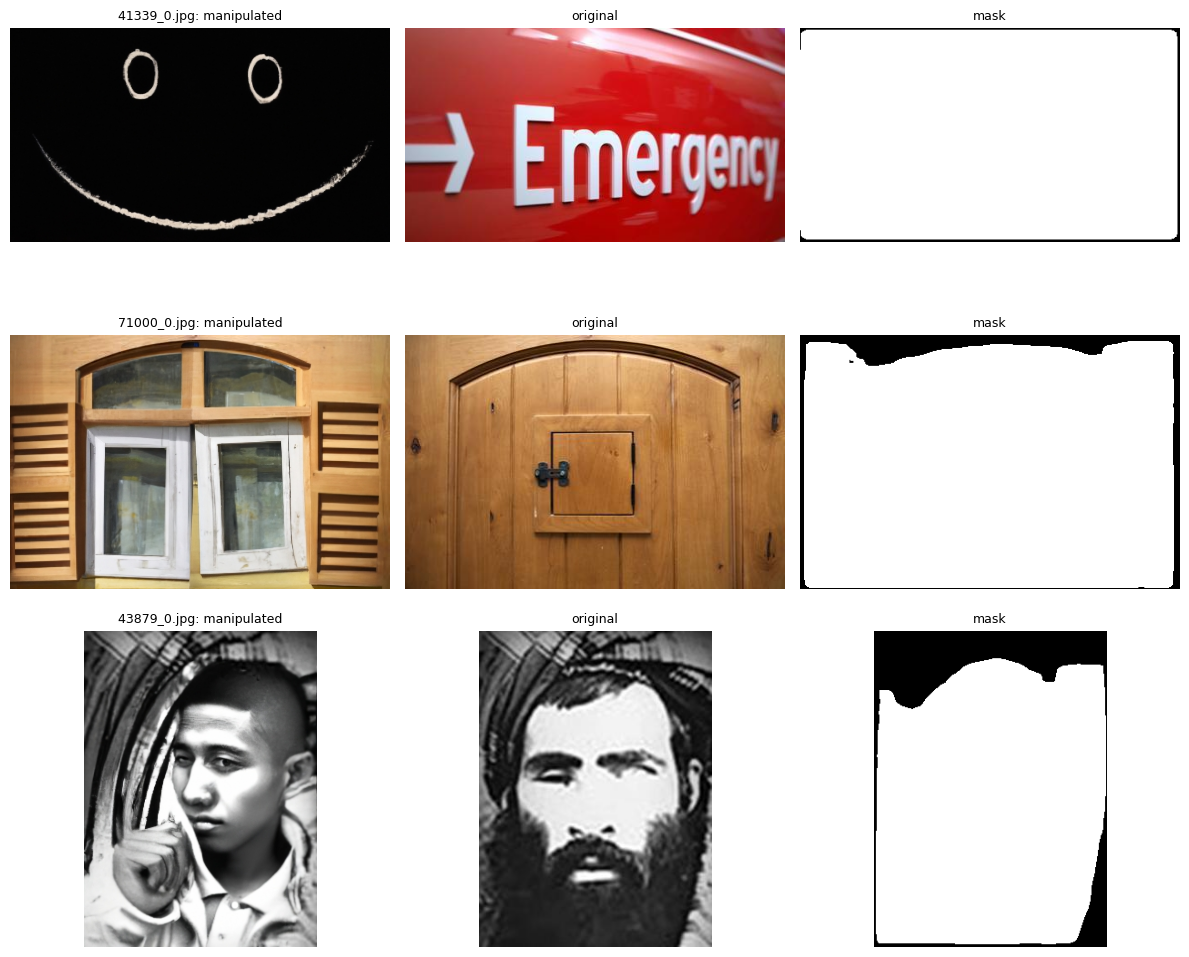

In [11]:
by_name = {Path(r["image_path"]).name: r for r in train_forged}
names = ["41339_0.jpg", "71000_0.jpg", "43879_0.jpg"]
fig, axes = plt.subplots(3, 3, figsize=(12, 10))
for row, name in enumerate(names):
    r = by_name[name]
    axes[row, 0].imshow(load_rgb(r["image_path"])); axes[row, 0].set_title(f"{name}: manipulated", fontsize=9)
    axes[row, 1].imshow(load_rgb(r["real_path"])); axes[row, 1].set_title("original", fontsize=9)
    axes[row, 2].imshow(load_binary_mask(r["mask_path"], foreground_value=mask_foreground), cmap="gray"); axes[row, 2].set_title("mask", fontsize=9)
    for ax in axes[row]:
        ax.axis("off")
plt.tight_layout()
plt.show()

### 6. 평가 규칙 확인

제안서는 평가를 원본 해상도, 임계값 0.5, 조작 이미지별 F1·IoU 평균, 정상 이미지 오탐률 분리로 정했지만, 빈 마스크·집계·해상도 처리의 세부 규칙은 정하지 않았다. 이 절은 train·val 조작 이미지에서 규칙이 필요한 경우가 실제로 얼마나 되는지 센다. 테스트 데이터는 사용하지 않는다.

빈 마스크는 조작 이미지인데 정답 마스크에 조작 픽셀이 하나도 없는 경우다. 이때 F1·IoU는 분모가 0이 되어 정의되지 않는다. 마스크 비율이 작은 이미지는 적은 픽셀의 오차에도 이미지별 F1이 크게 흔들린다. 

이미지 크기가 16 또는 32의 배수가 아니면 U-Net으로 원본 해상도를 그대로 예측할 때 패딩이 필요하다. 정상 이미지는 정답 마스크가 비어 있으므로 F1·IoU 없이 오탐률로만 평가한다는 제안서 방침을 따른다. 임계값 0.5는 예측 확률이 있어야 확인할 수 있어서 이 노트북에서 정하지 않고 학습 비교에서 확인한다.

In [12]:
def header_sizes(records):
    out = []
    for r in records:
        with Image.open(r["image_path"]) as a:
            out.append(a.size)
    return np.array(out)

val_masks = [load_binary_mask(r["mask_path"], foreground_value=mask_foreground) for r in val_forged]
rows = []
for name, masks, recs in (("train", train_masks, train_forged), ("val", val_masks, val_forged)):
    ratio = np.array([m.mean() for m in masks])
    wh = header_sizes(recs)
    rows.append({"split": name,
                 "조작 이미지 수": f"{len(masks):,}",
                 "빈 마스크 수": f"{int((ratio == 0).sum()):,}",
                 "마스크 비율 중앙값": f"{np.median(ratio):.3f}",
                 "마스크 비율 하위 10%": f"{np.quantile(ratio, 0.1):.3f}",
                 "비율 1% 미만 수": f"{int((ratio < 0.01).sum()):,}",
                 "16의 배수가 아닌 크기 비율": f"{((wh % 16 != 0).any(axis=1)).mean():.1%}",
                 "32의 배수가 아닌 크기 비율": f"{((wh % 32 != 0).any(axis=1)).mean():.1%}"})
display(pd.DataFrame(rows).set_index("split").T)

split,train,val
조작 이미지 수,"2,925",361
빈 마스크 수,0,0
마스크 비율 중앙값,0.442,0.417
마스크 비율 하위 10%,0.074,0.069
비율 1% 미만 수,0,0
16의 배수가 아닌 크기 비율,70.7%,66.8%
32의 배수가 아닌 크기 비율,72.7%,69.3%
